<a href="https://colab.research.google.com/github/zeynpakn/Taxi-v3-Q-Learning/blob/main/Taxi_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# 🚕 Taxi-v3 — Q-Learning

Training a tabular Q-Learning agent to pick up and drop off passengers in Gymnasium's Taxi-v3 environment.

Based on the Hugging Face Deep RL Course — Unit 2.


In [1]:

%pip -q install "gymnasium==1.2.0" matplotlib numpy pillow

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Gymnasium:", gym.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 944.3/944.3 kB 15.2 MB/s eta 0:00:00
Gymnasium: 1.2.0


In [2]:
# Taxi-v3 ortamini olusturuyoruz
env = gym.make("Taxi-v3", render_mode="ansi")
state, info = env.reset(seed=SEED)
env.action_space.seed(SEED)

print(env.render())
print("State:", state)
print("States:", env.observation_space.n)
print("Actions:", env.action_space.n)

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+


State: 386
States: 500
Actions: 6


In [3]:

# state ID'sini anlamli bilgilere ayiriyoruz
taxi_row, taxi_col, passenger_loc, destination = env.unwrapped.decode(state)

print("State ID:", state)
print("Taxi position:", (taxi_row, taxi_col))
print("Passenger location:", passenger_loc)
print("Destination:", destination)


State ID: 386
Taxi position: (3, 4)
Passenger location: 1
Destination: 2


In [4]:

# Taxi-v3'te kullanilabilen eylemler
actions = {
    0: "South",
    1: "North",
    2: "East",
    3: "West",
    4: "Pickup",
    5: "Dropoff"
}

for action_id, action_name in actions.items():
    print(f"{action_id}: {action_name}")


0: South
1: North
2: East
3: West
4: Pickup
5: Dropoff


In [5]:

# state-action sayisina gore bos Q-Table olusturur
def initialize_q_table(env):
    return np.zeros((env.observation_space.n, env.action_space.n))

q_table = initialize_q_table(env)

print("Q-Table shape:", q_table.shape)
print(q_table[:5])


Q-Table shape: (500, 6)
[[0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]]


In [6]:

# Q-Table'daki en yuksek degerli eylemi secer
def greedy_policy(q_table, state):
    return int(np.argmax(q_table[state]))

# epsilon olasiligiyla kesif, aksi halde en iyi eylem
def epsilon_greedy_policy(q_table, state, epsilon, env):
    if np.random.random() < epsilon:
        return env.action_space.sample()
    return greedy_policy(q_table, state)


In [7]:

# Q-Learning ile ajani egitir ve egitim gecmisini kaydeder
def train_q_learning(env, q_table, params):
    rewards, steps, epsilons = [], [], []
    epsilon = params["epsilon_start"]

    for episode in range(params["episodes"]):
        state, _ = env.reset()
        terminated = truncated = False
        total_reward, step_count = 0, 0

        while not (terminated or truncated):
            action = epsilon_greedy_policy(q_table, state, epsilon, env)
            next_state, reward, terminated, truncated, _ = env.step(action)

            # terminal durumda gelecek odulu hesaba katma
            next_q = 0 if terminated else np.max(q_table[next_state])

            # bellman hedefi ile Q degerini guncelle
            td_target = reward + params["gamma"] * next_q
            q_table[state, action] += params["learning_rate"] * (
                td_target - q_table[state, action]
            )

            state = next_state
            total_reward += reward
            step_count += 1

        rewards.append(total_reward)
        steps.append(step_count)
        epsilons.append(epsilon)
        epsilon = max(params["epsilon_min"], epsilon * params["epsilon_decay"])

    history = {
        "rewards": np.array(rewards),
        "steps": np.array(steps),
        "epsilons": np.array(epsilons)
    }

    return q_table, history


In [8]:

# Taxi-v3 egitim hiperparametreleri
training_params = {
    "episodes": 10000,
    "learning_rate": 0.7,
    "gamma": 0.95,
    "epsilon_start": 1.0,
    "epsilon_min": 0.01,
    "epsilon_decay": 0.999
}

# Q-Table'i egitiyoruz
q_table, history = train_q_learning(env, q_table, training_params)

print("Training completed!")
print("Average reward (first 100):", np.mean(history["rewards"][:100]))
print("Average reward (last 100):", np.mean(history["rewards"][-100:]))
print("Average steps (last 100):", np.mean(history["steps"][-100:]))


Training completed!
Average reward (first 100): -698.77
Average reward (last 100): 7.09
Average steps (last 100): 13.64


In [9]:

# egitilmis ajani yeni episode'larda test eder
def evaluate_agent(q_table, episodes=1000, seed=SEED):
    eval_env = gym.make("Taxi-v3")
    rewards, steps, successes = [], [], []

    for episode in range(episodes):
        state, _ = eval_env.reset(seed=seed + episode)
        terminated = truncated = False
        total_reward, step_count = 0, 0

        while not (terminated or truncated):
            action = greedy_policy(q_table, state)
            state, reward, terminated, truncated, _ = eval_env.step(action)

            total_reward += reward
            step_count += 1

        rewards.append(total_reward)
        steps.append(step_count)
        successes.append(terminated)

    eval_env.close()

    return {
        "success_rate": np.mean(successes),
        "mean_reward": np.mean(rewards),
        "std_reward": np.std(rewards),
        "mean_steps": np.mean(steps),
        "successful_steps": np.mean(np.array(steps)[np.array(successes)])
                            if any(successes) else 0
    }


In [10]:

# Taxi-v3 final evaluation
results = evaluate_agent(q_table, episodes=1000)

print("Evaluation Results 🚕")
print(f"Success Rate: {results['success_rate']:.2%}")
print(f"Mean Reward: {results['mean_reward']:.2f}")
print(f"Reward Standard Deviation: {results['std_reward']:.2f}")
print(f"Average Steps: {results['mean_steps']:.2f}")
print(f"Successful Episode Steps: {results['successful_steps']:.2f}")


Evaluation Results 🚕
Success Rate: 100.00%
Mean Reward: 7.84
Reward Standard Deviation: 2.62
Average Steps: 13.16
Successful Episode Steps: 13.16


In [11]:

# egitim odullerinin hareketli ortalamasini cizer
def plot_training_rewards(history, window=100):
    rewards = history["rewards"]
    moving_avg = np.convolve(rewards, np.ones(window) / window, mode="valid")
    episodes = np.arange(window, len(rewards) + 1)

    plt.figure(figsize=(10, 5))
    plt.plot(episodes, moving_avg, color="royalblue", label=f"{window}-Episode Moving Average")
    plt.axhline(0, color="gray", linestyle="--", alpha=0.5)

    plt.title("Taxi-v3 | Q-Learning Training Progress")
    plt.xlabel("Episode")
    plt.ylabel("Average Total Reward")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


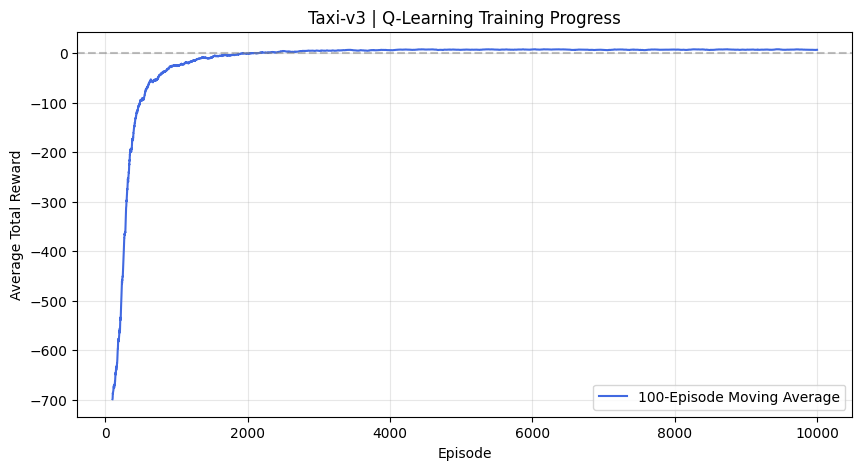

In [12]:

# Taxi-v3 egitim grafigi
plot_training_rewards(history)



### Training Progress

The agent's average reward improves rapidly during the early episodes, indicating that it is learning to avoid unnecessary actions and complete passenger deliveries.

After approximately 2,000 episodes, the learning curve becomes more stable and the average reward remains positive.

The final evaluation confirms this improvement, with a **100% success rate across 1,000 episodes**.


In [13]:

# ogrenilen politika ile bir episode oynar ve kareleri kaydeder
def record_episode(q_table, seed=SEED):
    demo_env = gym.make("Taxi-v3", render_mode="rgb_array")
    state, _ = demo_env.reset(seed=seed)

    frames = [demo_env.render()]
    actions_taken = []
    terminated = truncated = False
    total_reward = 0

    while not (terminated or truncated):
        action = greedy_policy(q_table, state)
        state, reward, terminated, truncated, _ = demo_env.step(action)

        actions_taken.append(actions[action])
        frames.append(demo_env.render())
        total_reward += reward

    demo_env.close()
    return frames, actions_taken, total_reward


In [14]:

# egitilmis taksinin bir oyununu kaydet
frames, actions_taken, demo_reward = record_episode(q_table)

print("Total Reward:", demo_reward)
print("Steps:", len(actions_taken))
print("Actions:", " → ".join(actions_taken))


/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


Total Reward: 8
Steps: 13
Actions: North → North → North → Pickup → West → South → West → South → West → West → South → South → Dropoff


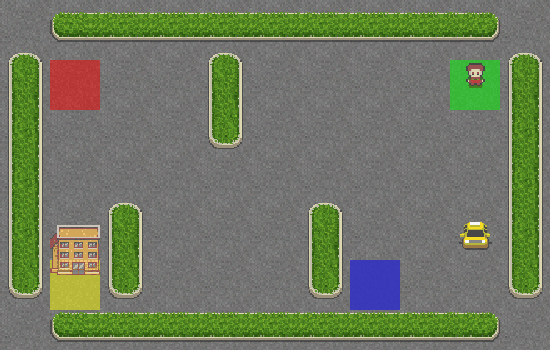

In [15]:

from PIL import Image as PILImage
from IPython.display import display, Image

# her kareyi 2 saniye goster
gif_frames = [PILImage.fromarray(frame) for frame in frames]

gif_frames[0].save(
    "taxi_q_learning.gif",
    save_all=True,
    append_images=gif_frames[1:],
    duration=350,
    loop=0
)

display(Image(filename="taxi_q_learning.gif"))


In [16]:

from collections import deque

# BFS ile hedefe ulasmak icin gereken minimum adimi bulur
def shortest_path_steps(env, start_state):
    queue = deque([(start_state, 0)])
    visited = {start_state}

    while queue:
        state, steps = queue.popleft()

        for action in range(env.action_space.n):
            for prob, next_state, reward, done in env.unwrapped.P[state][action]:
                if prob == 0:
                    continue
                if done and reward == 20:
                    return steps + 1
                if next_state not in visited:
                    visited.add(next_state)
                    queue.append((next_state, steps + 1))

    return None


In [17]:

# ogrenilen politika ile en kisa rotayi karsilastir
test_env = gym.make("Taxi-v3")
optimal_steps, learned_steps = [], []

for episode in range(1000):
    state, _ = test_env.reset(seed=SEED + episode)
    optimal_steps.append(shortest_path_steps(test_env, state))

    terminated = truncated = False
    steps = 0

    while not (terminated or truncated):
        action = greedy_policy(q_table, state)
        state, _, terminated, truncated, _ = test_env.step(action)
        steps += 1

    learned_steps.append(steps)

test_env.close()

optimal_steps = np.array(optimal_steps)
learned_steps = np.array(learned_steps)

print(f"Optimal Average Steps: {optimal_steps.mean():.2f}")
print(f"Learned Average Steps: {learned_steps.mean():.2f}")
print(f"Optimal Route Rate: {np.mean(learned_steps == optimal_steps):.2%}")
print(f"Average Extra Steps: {(learned_steps - optimal_steps).mean():.2f}")


Optimal Average Steps: 13.14
Learned Average Steps: 13.16
Optimal Route Rate: 98.90%
Average Extra Steps: 0.02



### Route Optimality Analysis

To evaluate policy efficiency, the learned routes were compared against the shortest paths calculated using Breadth-First Search (BFS).

The Q-Learning agent achieved a **98.9% optimal route rate** across 1,000 episodes, requiring only **0.02 additional steps on average**.

Combined with its **100% evaluation success rate**, these results show that the agent learned a highly effective and nearly optimal policy.
